### Figure 3: Vulnerable cluster condition $\kappa$ for ER graphs 

This code plots the contours of the vulnerable cluster condition $\kappa =1$ for ER topology with a threshold drawn from the beta distribution. We plot the $(z, \alpha_{th})$ phase space, where $z = \langle k \rangle $ is the average degree and $\alpha_{th}$ is the threshold skewness parameter, fixed at some constant $\beta_{th}$.


In [1]:
# Import statements
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, betabinom, beta as beta_dist
from figstyle import PALETTE, LW, REF_LW, FIGW_SINGLE, save

maximum degree kept is: 100


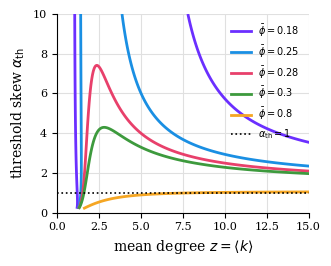

In [ ]:
# Parameter values for sweeping in (alpha, z)
alpha_vals = np.linspace(0.2, 10, 500)
z_vals = np.linspace(0.5, 25, 500)

# Fixed beta_th
B_th = 50

# Values of mean threshold to consider
phi_show = [0.18, 0.25, 0.28, 0.3,0.8]
colors_show = PALETTE[:len(phi_show)]

# Maximum degree considered. 
kmax_az = 100 # n.b. this is pretty arbitrary. It just needs to be large relative to sqrt(z),  ~ the variance of the poisson.
print(f'maximum degree kept is: {kmax_az}')

# range of k values to sum over
kk_az = np.arange(1, kmax_az + 1)

# This is [k(k-1)p_k * 1/z] iterated over all k and z. 
W = np.stack([kk_az * (kk_az - 1) / z * poisson.pmf(kk_az, z) for z in z_vals])

def kappa_grid(phi):
    'Compute kappa for a grid of (z,a_th) for a given phi_bar.'

    # The mean of the distribution
    m = alpha_vals / (alpha_vals + B_th) 

    # This is the upper limit of the RIBF, u = m/(k * phi). It is truncated to 1 above.
    arg = np.minimum(1.0, m[:, None] / (kk_az[None, :] * phi))  # The slicing here is for the matrix multiplication to work appropriately.
    
    # This is the CDF F(1/k)
    F = beta_dist.cdf(arg, alpha_vals[:, None], B_th)

    # Return kappa = sum on k of k(k-1) p_k /z F(1/k)
    return F @ W.T 

# Plot these contours for varying phi
fig, ax = plt.subplots(figsize=(FIGW_SINGLE, 2.7))
for phi, col in zip(phi_show, colors_show):
    K = kappa_grid(phi)
    ax.contour(z_vals, alpha_vals, K, levels=[1.0], colors=[col], linewidths=LW)
    ax.plot([], [], color=col, lw=LW, label=fr'$\bar\phi={phi}$')
ax.axhline(1.0, color="black", ls=":", lw=REF_LW, label=r'$\alpha_{\mathrm{th}}=1$')
ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.set_xlabel(r'mean degree $z=\langle k\rangle$')
ax.set_ylabel('threshold skew $\\alpha_{\\mathrm{th}}$')
ax.legend(loc="best", frameon=False, fontsize=7)
fig.tight_layout()
save(fig, "figure3")
plt.show()

Below, we run some numerical checks.

In [32]:
# We check that the truncation at kmax_az is appropriately large by lowering it and showing kappa is unchanged.
def kappa_grid_with_kmax(kmax):
    kk = np.arange(1, kmax + 1)
    W = np.stack([kk * (kk - 1) / z * poisson.pmf(kk, z) for z in z_vals])
    m = alpha_vals / (alpha_vals + B_th)
    arg = np.minimum(1.0, m[:, None] / (kk[None, :] * 0.25))
    return beta_dist.cdf(arg, alpha_vals[:, None], B_th) @ W.T

kappa_smaller_kmax = kappa_grid_with_kmax(kmax_az - 20)
kappa_reference = kappa_grid(0.25)
assert np.abs(kappa_smaller_kmax - kappa_reference).max() < 1e-6, "kmax_az truncation matters"
print(f"kmax_az = {kmax_az} is large enough.")

# We check that kappa decreases with alpha_th.
kappa = kappa_reference
region = z_vals >= 2.0
assert np.all(np.diff(kappa[:, region], axis=0) < 0), "kappa must decrease with alpha_th"
print("kappa decreases with alpha_th for z >= 2")

# We check that kappa grows with z below alpha_th = 1 and decays with z above it.
i_lo = np.argmin(abs(alpha_vals - 0.5))
i_hi = np.argmin(abs(alpha_vals - 2.0))
j_lo = np.argmin(abs(z_vals - 5))
j_hi = np.argmin(abs(z_vals - 20))
assert kappa[i_lo, j_hi] > kappa[i_lo, j_lo], "kappa should grow with z for alpha_th = 0.5"
assert kappa[i_hi, j_hi] < kappa[i_hi, j_lo], "kappa should decay with z for alpha_th = 2.0"
print(f"Kappa grows in z below alpha_th=1.")
print(f"Kappa decays in z above alpha_th=1.")


# We check that each contour crosses kappa = 1 exactly once in alpha_th at z = 20.
for phi in phi_show:
    column = kappa_grid(phi)[:, j_hi]
    assert np.sum(np.diff(np.sign(column - 1.0)) != 0) == 1, f"expected one kappa=1 crossing at phi={phi}"
print("Each contour crosses kappa = 1 exactly once.")

# We check that the alpha_th = 1 limit matches beta_th / ((1 + beta_th) phi_bar), and asymptotically approaches it from below correctly.
def kappa_at(large_z, alpha_th, phi=0.25):
    kmax = int(large_z + 10 * np.sqrt(large_z) + 10)
    kk = np.arange(1, kmax + 1)
    weights = kk * (kk - 1) / large_z * poisson.pmf(kk, large_z)
    m = alpha_th / (alpha_th + B_th)
    arg = np.minimum(1.0, m / (kk * phi))
    return beta_dist.cdf(arg, alpha_th, B_th) @ weights

predicted = B_th / ((1 + B_th) * 0.25)
ratios = [kappa_at(z, 1.0) / predicted for z in (1e3, 1e4, 1e5)]
assert all(r < 1 for r in ratios), "alpha_th = 1 limit must be approached from below"
assert all(np.diff(ratios) > 0), "alpha_th = 1 ratio must increase monotonically towards the limit"
assert ratios[-1] > 0.999, "alpha_th = 1 limit not reached at z = 1e5"

print(f"The value of the kappa at the critical boundary alpha_th=1 converges to the claimed critical phi bar appropriately.")

kmax_az = 100 is large enough.
kappa decreases with alpha_th for z >= 2
Kappa grows in z below alpha_th=1.
Kappa decays in z above alpha_th=1.
Each contour crosses kappa = 1 exactly once.
The value of the kappa at the critical boundary alpha_th=1 converges to the claimed critical phi bar appropriately.
